<a href="https://colab.research.google.com/github/MohammedAyman07/curriculum-rag-research/blob/main/notebooks/05_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CurriculumRAG — Final Evaluation

## Objective
Compare TF-IDF, Dense Semantic Retrieval, and Hybrid RRF.

## Evaluation dataset
15 development questions.

## Metrics
- Precision@5
- Recall@5
- Mean Reciprocal Rank
- Hit@1
- Median Query Latency

## Additional Analysis
- Per-question ranking errors
- Method comparison
- Performance visualisation

In [1]:

# CurriculumRAG - Load experiment results

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "MohammedAyman07/curriculum-rag-research/main/"
)

RESULTS_URL = BASE_URL + "results/"
DATA_URL = BASE_URL + "data/"

# Load metric summaries
tfidf_metrics = pd.read_csv(
    RESULTS_URL + "tfidf_dev_metrics.csv"
)

dense_metrics = pd.read_csv(
    RESULTS_URL + "dense_dev_metrics.csv"
)

hybrid_metrics = pd.read_csv(
    RESULTS_URL + "hybrid_dev_metrics.csv"
)

# Load individual query predictions
tfidf_predictions = pd.read_csv(
    RESULTS_URL + "tfidf_dev_predictions.csv"
)

dense_predictions = pd.read_csv(
    RESULTS_URL + "dense_dev_predictions.csv"
)

hybrid_predictions = pd.read_csv(
    RESULTS_URL + "hybrid_dev_predictions.csv"
)

# Load original query dataset
queries_df = pd.read_csv(DATA_URL + "queries.csv")

print("All experiment results loaded!")
print("TF-IDF predictions:", len(tfidf_predictions))
print("Dense predictions:", len(dense_predictions))
print("Hybrid predictions:", len(hybrid_predictions))


All experiment results loaded!
TF-IDF predictions: 15
Dense predictions: 15
Hybrid predictions: 15


In [2]:

# Validate all three experiment datasets

prediction_sets = {
    "TF-IDF": tfidf_predictions,
    "Dense": dense_predictions,
    "Hybrid": hybrid_predictions
}

dev_ids = set(
    queries_df.loc[
        queries_df["split"] == "dev", "query_id"
    ]
)

for method, df in prediction_sets.items():

    assert len(df) == 15, f"{method}: Expected 15 predictions"

    assert df["query_id"].is_unique, (
        f"{method}: Duplicate query IDs"
    )

    assert set(df["query_id"]) == dev_ids, (
        f"{method}: Development query mismatch"
    )

# Confirm all methods use identical relevance labels
reference = tfidf_predictions.set_index("query_id")

for method, df in list(prediction_sets.items())[1:]:

    candidate = df.set_index("query_id")

    assert (
        reference["relevant_doc_ids"].sort_index()
        == candidate["relevant_doc_ids"].sort_index()
    ).all(), f"{method}: Relevance labels differ"

print("Validation passed!")
print("All methods use the same 15 development questions.")
print("No held-out test questions are included.")


Validation passed!
All methods use the same 15 development questions.
No held-out test questions are included.


In [3]:

# Calculate Hit@1 directly from the predictions

def get_rank(retrieved_ids, relevant_ids):

    retrieved = str(retrieved_ids).split("|")
    relevant = set(str(relevant_ids).split("|"))

    for rank, doc_id in enumerate(retrieved, start=1):

        if doc_id in relevant:
            return rank

    return None


def calculate_hit_at_1(df):

    hits = []

    for _, row in df.iterrows():

        rank = get_rank(
            row["retrieved_doc_ids"],
            row["relevant_doc_ids"]
        )

        hits.append(1 if rank == 1 else 0)

    return np.mean(hits)


comparison_df = pd.DataFrame([
    {
        "Method": "TF-IDF",
        "Precision@5": tfidf_metrics.loc[0, "Precision@5"],
        "Recall@5": tfidf_metrics.loc[0, "Recall@5"],
        "MRR": tfidf_metrics.loc[0, "MRR"],
        "Hit@1": calculate_hit_at_1(tfidf_predictions),
        "Median Latency (ms)": tfidf_metrics.loc[
            0, "Median Query Latency (ms)"
        ]
    },
    {
        "Method": "Dense",
        "Precision@5": dense_metrics.loc[0, "Precision@5"],
        "Recall@5": dense_metrics.loc[0, "Recall@5"],
        "MRR": dense_metrics.loc[0, "MRR"],
        "Hit@1": calculate_hit_at_1(dense_predictions),
        "Median Latency (ms)": dense_metrics.loc[
            0, "Median Query Latency (ms)"
        ]
    },
    {
        "Method": "Hybrid RRF",
        "Precision@5": hybrid_metrics.loc[0, "Precision@5"],
        "Recall@5": hybrid_metrics.loc[0, "Recall@5"],
        "MRR": hybrid_metrics.loc[0, "MRR"],
        "Hit@1": calculate_hit_at_1(hybrid_predictions),
        "Median Latency (ms)": hybrid_metrics.loc[
            0, "Median Query Latency (ms)"
        ]
    }
])

print("Final development comparison")
display(comparison_df.round(4))


Final development comparison


,Method,Precision@5,Recall@5,MRR,Hit@1,Median Latency (ms)
0,TF-IDF,0.2,1.0,0.8056,0.6667,1.2796
1,Dense,0.2,1.0,0.9667,0.9333,44.3653
2,Hybrid RRF,0.2,1.0,0.9667,0.9333,55.8701


In [4]:

# Find questions where the relevant passage is not ranked first

error_records = []

for method, df in prediction_sets.items():

    for _, row in df.iterrows():

        rank = get_rank(
            row["retrieved_doc_ids"],
            row["relevant_doc_ids"]
        )

        if rank != 1:

            error_records.append({
                "Method": method,
                "Query ID": row["query_id"],
                "Question": row["question"],
                "Relevant Passage": row["relevant_doc_ids"],
                "Retrieved Passages": row["retrieved_doc_ids"],
                "Correct Passage Rank": rank
            })


error_df = pd.DataFrame(error_records)

print("Questions not ranked correctly at position 1:")
display(error_df)

print("\nTotal ranking errors:", len(error_df))


Questions not ranked correctly at position 1:


,Method,Query ID,Question,Relevant Passage,Retrieved Passages,Correct Passage Rank
0,TF-IDF,Q010,Where does a queue insert new elements and rem...,P010,P040|P025|P010|P019|P032,3
1,TF-IDF,Q013,How many children can a node have in a binary ...,P013,P014|P013|P016|P015|P030,2
2,TF-IDF,Q020,Which graph traversal visits nearby vertices b...,P019,P016|P019|P020|P013|P017,2
3,TF-IDF,Q022,How does DFS explore a graph and then return t...,P020,P019|P018|P023|P020|P017,4
4,TF-IDF,Q038,Why must a collection be sorted before applyin...,P033,P015|P033|P014|P030|P020,2
5,Dense,Q006,Which linked list supports traversal in both d...,P006,P005|P006|P007|P016|P036,2
6,Hybrid,Q022,How does DFS explore a graph and then return t...,P020,P019|P020|P018|P017|P023,2



Total ranking errors: 7


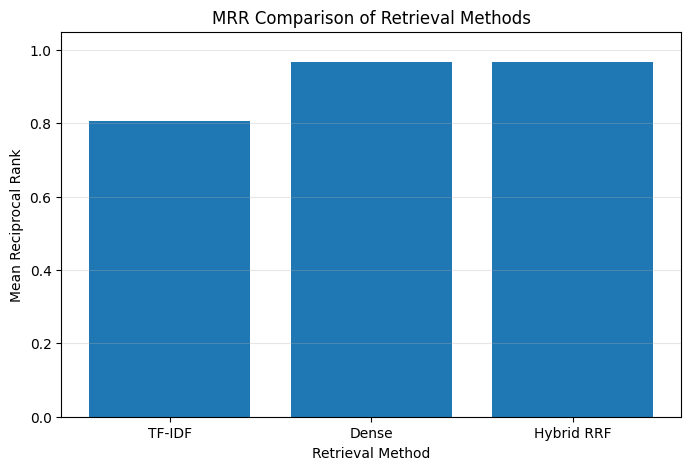

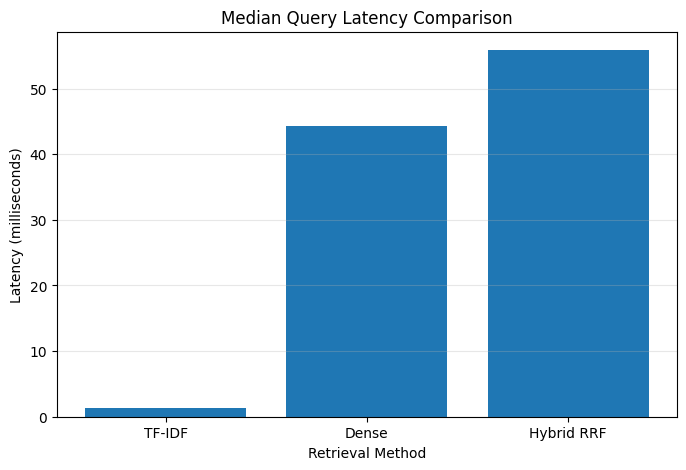

In [5]:

# MRR comparison chart

plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Method"],
    comparison_df["MRR"]
)

plt.title("MRR Comparison of Retrieval Methods")
plt.xlabel("Retrieval Method")
plt.ylabel("Mean Reciprocal Rank")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)

plt.show()


# Query latency comparison chart

plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Method"],
    comparison_df["Median Latency (ms)"]
)

plt.title("Median Query Latency Comparison")
plt.xlabel("Retrieval Method")
plt.ylabel("Latency (milliseconds)")
plt.grid(axis="y", alpha=0.3)

plt.show()


In [6]:

# Save final development comparison and error analysis

OUTPUT_DIR = Path("/content/curriculum-rag-results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    OUTPUT_DIR / "dev_method_comparison.csv",
    index=False
)

error_df.to_csv(
    OUTPUT_DIR / "dev_query_error_analysis.csv",
    index=False
)

print("Evaluation files saved!")

print("1. dev_method_comparison.csv")
print("2. dev_query_error_analysis.csv")


Evaluation files saved!
1. dev_method_comparison.csv
2. dev_query_error_analysis.csv
